# Phase 6Q-2 (Qwen3-8B): runtime validator

**Goal:** the decisive control. Every KiL pipeline (shallow, semi-deep, deep) must beat this arm, not just the baseline. Same settings as the baseline (05Q); the only change is the validator.

**Pipeline (example: cancel a flight):**

```
user input → [prompt = prose policy, as in 05Q] → Qwen3-8B → tool call
                                                              ↓
                              write call? → validator (the graph's 24 data rules as code)
                                              ↓ rule holds          ↓ rule broken
                                           database runs it     call is blocked; the agent gets
                                                                 the name of the broken rule
```

The validator only sees tool calls. It cannot see the dialogue, so it cannot catch a skipped explanation or a missing "yes" (that is semi-deep's job).

**Spec check (brief → this notebook):**

| Brief says | This notebook | Same? |
|---|---|---|
| "Stock agent + runtime validator": "the decisive control: the same policy graph as code that blocks illegal tool calls" | 05Q's agent and prompt; `policy_checker.py` (the graph's 24 data rules) checks every write call before it reaches the database | yes |
| "illegal tool calls (a validator can catch these)" | blocked calls are counted per trial; illegal calls that still ran should be 0 | yes |
| "If the validator matches the KiL systems, the conclusion is that tool-level policy belongs in code" | this arm is the line 07Q–09Q are compared with in 10Q; here it is compared with 05Q (paired, 95% CI) | yes |
| "Run each task at least 8 times with different simulator seeds" | 50 tasks × 8 trials; trials differ by the user simulator's sampling, not by fixed seeds | partly: same goal, no fixed seeds |
| Office hour: Qwen, not Gemini | agent = Qwen3-8B | yes |

**Who plays which role:**

| Role | Model | Settings |
|---|---|---|
| Agent (the airline agent being tested) | **Qwen3-8B** on vLLM 0.34.0 | thinking off, temperature 0.0, hermes tool parser |
| Validator | `policy_checker.py` (code, no model) | 24 data rules from `airline_policy_graph.json` |
| Customer (the user simulator) | **Gemini** `gemini-3.1-flash-lite` | temperature: to confirm in `deep_run.py` |

**Run first:** 04, 06G (`policy_checker.py`, `violations.py`), 05Q (its results are the comparison line). **Runtime:** L4 or larger; on an L4 the vLLM cell uses a 24k context and `--max-num-seqs 8`, and records both. **Time and cost on an L4:** about 3.0 h, about $1.4 for the Gemini user simulator. Blocked calls make dialogues longer, so one may hit the 24k limit; cell 7 then shows it as "not done". Run cell 7 once more; if it fails again, count it as a fail and do not keep rerunning.

**Only re-analysing saved results?** Run cells 1, 2, 3, 8, 9, 10, 11, 12. No GPU server needed.

**Output:** `results_qwen_validator/trial_1..8/` (dialogues, `calls.jsonl`, `blocks.jsonl`), plus `results_qwen_validator_config.json`, `_vllm.json`, `_passk.csv`, `_vs_base.csv`, `_violations.json` and `_consistency.json` for 10Q. Safe to stop: finished tasks are skipped.

In [1]:
# Why: results and code live on Google Drive, so they survive when the Colab runtime resets.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Why: make sure every package the Qwen notebooks need is present, checked one by one. Colab images
# sometimes ship vLLM without litellm, so a single vLLM check lets cell 4 die on `import litellm`.
# Only missing packages get installed; vLLM takes a few minutes, the rest are quick.
import importlib, importlib.util, site, subprocess
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
PKGS = [("tau_bench", f"-e {ROOT}"), ("litellm", "litellm"), ("vllm", "vllm"),
        ("peft", "peft"), ("mcp", "mcp")]

def have(mod):
    importlib.invalidate_caches()
    try:
        site.main()            # pick up what pip just added to this running kernel
    except Exception:
        pass
    try:
        return importlib.util.find_spec(mod) is not None
    except Exception:
        return False

def pip_install(spec):
    r = subprocess.run(f"pip install -q {spec}", shell=True, capture_output=True, text=True, cwd=ROOT)
    return [l for l in (r.stdout + r.stderr).splitlines()
            if "error" in l.lower() and "protobuf" not in l.lower()]

rows, errors = [], []
for mod, spec in PKGS:
    if have(mod):
        rows.append({"package": mod, "action": "already there"})
        continue
    errors += pip_install(spec)
    if mod == "vllm":
        subprocess.run("pip uninstall -y -q torchao", shell=True, capture_output=True)  # clashes with vLLM
    rows.append({"package": mod, "action": "installed" if have(mod) else "❌ still missing"})

display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
if errors:
    print("\n".join(errors[-5:]))

package,action
tau_bench,installed
litellm,already there
vllm,installed
peft,already there
mcp,already there


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


In [3]:
# Why: every arm must use the same frozen settings, or the comparison is not fair. The agent
# settings come from settings_deep.py and settings_gemini.py. The agent temperature is set here
# once and used by cells 4 and 5; an assert stops the run if it ever drifts from settings_gemini.
# BASE_OUT is 05Q's baseline: cells 9-12 compare with it but never write to it.
# The Gemini key comes from Colab Secrets and is never printed.
import os, sys, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT)
os.chdir(ROOT)
NEED = ["settings_gemini.py", "settings_deep.py", "deep_run.py", "policy_checker.py",
        "violations.py", "airline_policy_graph.json", "passk.py"]
missing = [f for f in NEED if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 04 and 06G first; settings_deep.py and deep_run.py must be in the folder"

importlib.invalidate_caches()
import settings_gemini, settings_deep
importlib.reload(settings_gemini); importlib.reload(settings_deep)
from settings_gemini import (MODEL as USER_MODEL, ENV, N_TASKS, N_TRIALS,
                             TEMPERATURE, CONCURRENCY, PRICE_IN, PRICE_OUT)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, AGENT_THINKING

AGENT_TEMP = 0.0                                    # one source of truth for cells 4 and 5
assert TEMPERATURE == AGENT_TEMP, f"settings_gemini.TEMPERATURE is {TEMPERATURE}, expected {AGENT_TEMP}"
USER_TEMP = "not set in settings_*.py (check deep_run.py)"   # fill in after the grep
ARM, OUT, BASE_OUT = "validator", "results_qwen_validator", "results_qwen_base"
ARMS = [(f"qwen {ARM} (06Q)", OUT, "#f47230"),      # name, folder, color (H7); this arm first
        ("qwen base (05Q)", BASE_OUT, "#257de0")]   # comparison only, never written to

warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)
from google.colab import userdata
os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"

def show(df):
    display(df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

_TAB = {}
def tab_of(folder, reload=False):
    # read the saved dialogues off Drive once; cells 8-12 share the copy
    import passk
    if reload or folder not in _TAB:
        importlib.reload(passk)
        _TAB[folder] = passk.table(f"{ROOT}/{folder}")
    return _TAB[folder]

show(pd.DataFrame([
    {"setting": "agent model", "value": f"{BASE_MODEL} (served as {SERVED_BASE}), thinking {AGENT_THINKING}"},
    {"setting": "agent temperature", "value": str(AGENT_TEMP)},
    {"setting": "validator", "value": "on: policy_checker.py (24 data rules) blocks illegal write calls"},
    {"setting": "user simulator", "value": f"{USER_MODEL} (Gemini, same as every arm)"},
    {"setting": "user temperature", "value": USER_TEMP},
    {"setting": "env / tasks / trials", "value": f"{ENV} / {N_TASKS} / {N_TRIALS}"},
    {"setting": "concurrency", "value": str(CONCURRENCY)},
    {"setting": "output folder", "value": OUT},
    {"setting": "compared with", "value": f"{BASE_OUT} " + ("(found)" if os.path.isdir(f"{ROOT}/{BASE_OUT}") else "⚠️ not found: run 05Q first")},
]))

setting,value
agent model,"Qwen/Qwen3-8B (served as qwen3-8b), thinking False"
agent temperature,0.0
validator,on: policy_checker.py (24 data rules) blocks illegal write calls
user simulator,"gemini-3.1-flash-lite (Gemini, same as every arm)"
user temperature,not set in settings_*.py (check deep_run.py)
env / tasks / trials,airline / 50 / 8
concurrency,4
output folder,results_qwen_validator
compared with,results_qwen_base (found)


In [4]:
# Why: start Qwen3-8B on vLLM and test it. The GPU decides the settings: >= 40 GB (A100, G4, H100)
# uses the full 32k context; a 24 GB L4 only fits 24k (recorded in the config).
# max-num-seqs is capped at 2 x concurrency: the default (256) reserves warmup memory we never use,
# and on an L4 that leaves too little KV cache for 24k. The vLLM version is saved, since a newer
# vLLM can behave differently from the one an earlier arm used.
# Not needed to re-analyse saved results: for that, run cells 1, 2, 3, 8, 11, 12 only.
import subprocess, time, json, urllib.request, importlib.metadata, litellm
os.makedirs(f"{ROOT}/logs_qwen", exist_ok=True)
smi = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout.strip()
assert ", " in smi, "no GPU found: Runtime > Change runtime type > pick a GPU"
GPU_NAME, gb = smi.splitlines()[0].split(", ")
GPU_GB = int(gb) / 1024
RUN_LEN, RUN_MEM = (MAX_MODEL_LEN, GPU_MEM) if GPU_GB >= 39 else (24576, "0.93")
MAX_SEQS = 2 * CONCURRENCY
VLLM_VER = importlib.metadata.version("vllm")
VLLM_LOG = f"{ROOT}/logs_qwen/vllm.log"
json.dump({"vllm": VLLM_VER, "max_num_seqs": MAX_SEQS, "gpu": GPU_NAME, "max_model_len": RUN_LEN},
          open(f"{ROOT}/{OUT}_vllm.json", "w"), indent=2)

def server_up():
    try:
        urllib.request.urlopen("http://localhost:8000/v1/models", timeout=5); return True
    except Exception:
        return False

t0 = time.time()
reused = server_up()
if not reused:
    cmd = (f"vllm serve {BASE_MODEL} --served-model-name {SERVED_BASE} --max-model-len {RUN_LEN} "
           f"--gpu-memory-utilization {RUN_MEM} --max-num-seqs {MAX_SEQS} "
           f"--enable-auto-tool-choice --tool-call-parser hermes --port 8000")
    with open(VLLM_LOG, "w") as lf:               # the server keeps its own handle; ours is closed
        server = subprocess.Popen(cmd, shell=True, stdout=lf, stderr=subprocess.STDOUT)
    while not server_up():
        if server.poll() is not None or time.time() - t0 > 1200:
            err = [l for l in open(VLLM_LOG).read().splitlines() if "error" in l.lower()][-3:]
            raise RuntimeError("vLLM did not start. Last errors in logs_qwen/vllm.log:\n" + "\n".join(err))
        time.sleep(10)

kw = dict(model=SERVED_BASE, custom_llm_provider="hosted_vllm", api_base=os.environ["VLLM_BASE"], api_key="none",
          temperature=AGENT_TEMP, extra_body={"chat_template_kwargs": {"enable_thinking": AGENT_THINKING}})
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
msg = [{"role": "user", "content": "Look up reservation ABC123."}]
r1 = litellm.completion(**kw, tools=tools, messages=msg)
try:
    r2 = litellm.completion(**kw, tools=tools, tool_choice="none", messages=msg)
    none_ok = "✅" if not r2.choices[0].message.tool_calls else "⚠️ returned a call (ignored by kil_qwen.py)"
except Exception as e:
    none_ok = f"⚠️ not supported ({type(e).__name__}); kil_qwen.py falls back"
show(pd.DataFrame([
    {"check": "GPU", "result": f"{GPU_NAME}, {GPU_GB:.0f} GB"},
    {"check": "vLLM version", "result": VLLM_VER},
    {"check": "max length", "result": f"{RUN_LEN}" + ("" if RUN_LEN == MAX_MODEL_LEN else "  ⚠️ full setting is 32768: note in the report")},
    {"check": "max num seqs", "result": str(MAX_SEQS)},
    {"check": "vLLM", "result": "reused (already running)" if reused else f"started in {(time.time() - t0) / 60:.1f} min"},
    {"check": "tool call", "result": "✅" if r1.choices[0].message.tool_calls else "❌"},
    {"check": "text-only call (semi-deep needs it)", "result": none_ok}]))

check,result
GPU,"NVIDIA L4, 22 GB"
vLLM version,0.34.0
max length,24576 ⚠️ full setting is 32768: note in the report
max num seqs,8
vLLM,started in 4.6 min
tool call,✅
text-only call (semi-deep needs it),✅


In [5]:
# Why: one function runs this arm for 8 trials x 50 tasks, one folder per trial, with
# deep_run.py (agent -> Qwen on vLLM, user -> Gemini). VALIDATOR = True switches 06G's checker on:
# every write call is checked first, and a blocked call is logged to blocks.jsonl.
# Finished tasks are skipped, so a stopped run can simply be started again. The config is written
# only when a task really runs, so a rerun of a finished arm never overwrites its config.
import time, json, importlib, passk; importlib.reload(passk)
VALIDATOR = True

def run_arm(out, tasks=None, trials=None, arm=ARM):
    os.environ["DEEP_VALIDATOR"] = "1" if VALIDATOR else "0"
    config = {"agent": BASE_MODEL, "user": USER_MODEL, "arm": arm, "validator": VALIDATOR,
              "agent_temperature": AGENT_TEMP, "user_temperature": USER_TEMP,
              "gpu": GPU_NAME, "max_model_len": RUN_LEN, "max_num_seqs": MAX_SEQS, "vllm": VLLM_VER}
    rows, wrote = [], False
    for trial in (trials or range(1, N_TRIALS + 1)):
        folder = f"{ROOT}/{out}/trial_{trial}"
        os.makedirs(folder, exist_ok=True)
        want = set(tasks if tasks is not None else range(N_TASKS))
        todo = sorted(want - passk.done_tasks(folder))
        if not todo:
            rows.append({"trial": trial, "ran": 0, "min": "-", "not done": 0, "note": "already done"})
            continue
        if not wrote:
            json.dump(config, open(f"{ROOT}/{out}_config.json", "w"), indent=2); wrote = True
        print(f"trial {trial}: running {len(todo)} tasks ...", flush=True)
        t0 = time.time()
        os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
        os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
        ids = " ".join(map(str, todo))
        log = f"{ROOT}/logs_qwen/{out}_trial_{trial}.log"
        !cd {ROOT} && python deep_run.py --env {ENV} --agent-strategy tool-calling \
          --model {SERVED_BASE} --model-provider hosted_vllm \
          --user-model {USER_MODEL} --user-model-provider gemini \
          --user-strategy llm --num-trials 1 --temperature {AGENT_TEMP} \
          --task-ids {ids} --max-concurrency {CONCURRENCY} \
          --log-dir {folder} >> {log} 2>&1
        left = len(want - passk.done_tasks(folder))
        note = ""
        if left:
            bad = [l for l in open(log).read().splitlines() if "Error" in l or "Traceback" in l][-1:]
            note = bad[0][:80] if bad else f"see logs_qwen/{out}_trial_{trial}.log"
        rows.append({"trial": trial, "ran": len(todo), "min": f"{(time.time() - t0) / 60:.1f}",
                     "not done": left, "note": note})
    _TAB.pop(out, None)                           # results changed: drop the cached dialogues
    show(pd.DataFrame(rows))

def n_blocks(folder):
    f = f"{folder}/blocks.jsonl"
    return sum(1 for l in open(f) if l.strip()) if os.path.exists(f) else 0

In [6]:
# Why: a 2-task smoke test before the full run: do dialogues finish, any API errors, is the
# validator really on (blocks.jsonl is written when it blocks), and how long and how much the full
# run will take. The time formula matched the real 05Q run (2.6 h on L4).
import shutil
SMOKE = f"{OUT}_smoke"
shutil.rmtree(f"{ROOT}/{SMOKE}", ignore_errors=True)
t0 = time.time()
run_arm(SMOKE, tasks=[0, 1], trials=[1])
sec = time.time() - t0
tab = tab_of(SMOKE, reload=True)
done = sum(len(v) for v in tab.values())
errs = sum(passk.is_error(r) for v in tab.values() for r in v.values())
cl = f"{ROOT}/{SMOKE}/trial_1/calls.jsonl"
calls = [json.loads(l) for l in open(cl)] if os.path.exists(cl) else []
usd = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls if c["who"] == "user") / 1e6
cfg = json.load(open(f"{ROOT}/{SMOKE}_config.json"))
show(pd.DataFrame([{"dialogues done": f"{done}/2", "API errors": errs,
                    "validator in config": cfg["validator"],
                    "blocked calls": n_blocks(f"{ROOT}/{SMOKE}/trial_1"),
                    "est. full run": f"{sec / max(done, 1) * N_TASKS * N_TRIALS / CONCURRENCY / 3600:.1f} h",
                    "est. Gemini cost": f"${usd / max(done, 1) * N_TASKS * N_TRIALS:.2f}",
                    "go on?": "✅ run the next cell" if done == 2 and errs == 0 and cfg["validator"] else "❌ check the log"}]))

trial 1: running 2 tasks ...


trial,ran,min,not done,note
1,2,3.8,0,


dialogues done,API errors,validator in config,blocked calls,est. full run,est. Gemini cost,go on?
2/2,0,True,5,3.2 h,$1.38,✅ run the next cell


In [13]:
# Why: the full run (8 trials x 50 tasks).
run_arm(OUT)

trial 8: running 1 tasks ...


trial,ran,min,not done,note
1,0,-,0,already done
2,0,-,0,already done
3,0,-,0,already done
4,0,-,0,already done
5,0,-,0,already done
6,0,-,0,already done
7,0,-,0,already done
8,1,1.6,0,


In [14]:
# Why: see at a glance whether every trial finished, how many API errors there were (an error
# counts as a fail, so those tasks must be run again), and how often the validator blocked a call.
tab = tab_of(OUT, reload=True)
show(pd.DataFrame([{"trial": t, "done": f"{len(tab.get(t, {}))}/{N_TASKS}",
                    "passed": sum(x["reward"] >= 1 - 1e-6 for x in tab.get(t, {}).values()),
                    "API errors": sum(passk.is_error(x) for x in tab.get(t, {}).values()),
                    "blocked calls": n_blocks(f"{ROOT}/{OUT}/trial_{t}")}
                   for t in range(1, N_TRIALS + 1)]))

trial,done,passed,API errors,blocked calls
1,50/50,20,0,44
2,50/50,20,0,57
3,50/50,21,0,51
4,50/50,17,0,38
5,50/50,18,0,38
6,50/50,17,0,45
7,50/50,20,0,38
8,50/50,19,0,36


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,95% CI k=1,drop 1→8
qwen validator (06Q),0.380,0.296,0.260,0.239,0.226,0.216,0.207,0.200,"[0.27, 0.49]",47%
qwen base (05Q),0.150,0.071,0.039,0.022,0.013,0.006,0.003,0.000,"[0.09, 0.22]",100%


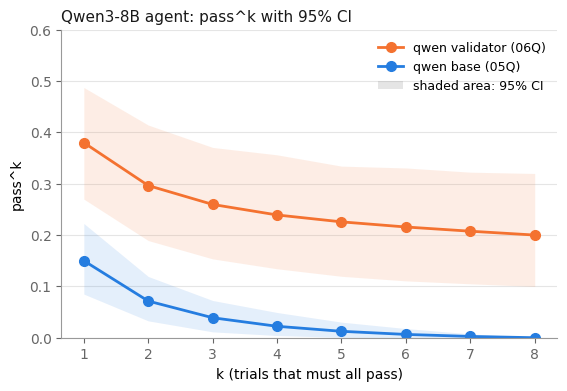

In [15]:
# Why: pass^k (k = 1..8) with 95% CI is the headline metric. The baseline (05Q) is drawn in the same
# chart for comparison. ylim stays fixed at 0.6 so every Qwen notebook draws on the same axis (H7).
# Only this arm's csv is written; 05Q's files are never touched.
import csv, matplotlib.pyplot as plt
from matplotlib.patches import Patch
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS}
show(pd.DataFrame([{"arm": n, **{f"k={r['k']}": f"{r['pass^k']:.3f}" for r in rows},
                    "95% CI k=1": f"[{rows[0]['ci_low']:.2f}, {rows[0]['ci_high']:.2f}]",
                    "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}" if rows[0]["pass^k"] else "-"}
                   for n, rows in curves.items() if rows]))
r = curves[ARMS[0][0]]
if r:
    with open(f"{ROOT}/{OUT}_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=r[0].keys()); w.writeheader(); w.writerows(r)
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, d, color in ARMS:
    r = curves[name]
    if not r: continue
    ks = [x["k"] for x in r]
    ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], color=color, alpha=0.12, lw=0)
    ax.plot(ks, [x["pass^k"] for x in r], "-", marker="o", ms=7, lw=2, color=color, label=name)
ax.set(xlabel="k (trials that must all pass)", ylabel="pass^k", ylim=(0, 0.6), xticks=range(1, 9))
ax.set_title("Qwen3-8B agent: pass^k with 95% CI", loc="left", fontsize=11, color="#191919")
ax.spines[["top", "right"]].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#999999")
ax.tick_params(colors="#666666"); ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#999999", alpha=0.25, label="shaded area: 95% CI"))
ax.legend(handles=handles, frameon=False, fontsize=9)
os.makedirs(f"{ROOT}/figures", exist_ok=True)
plt.savefig(f"{ROOT}/figures/{OUT}_passk.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
# Why: H1 compares every arm with the validator, so the headline question here is: does the validator
# beat the baseline on the same tasks? Paired over tasks: per task, pass^k = C(c, k) / C(8, k)
# (c = passes in 8 trials), then the mean difference with a 95% bootstrap CI over tasks
# (10,000 resamples, fixed seed). Shown for all 50 tasks and for the 42 clean tasks (8 tasks have
# answer keys that break the policy). The table is saved for 10Q.
import numpy as np
from math import comb
BAD_KEYS = {10, 16, 19, 26, 27, 34, 45, 46}         # answer keys that break the policy (Part 1, 06G)
KS = [1, 2, 4, 8]

def per_task(folder):
    full = {t: v for t, v in tab_of(folder).items() if len(v) == N_TASKS}
    assert len(full) == N_TRIALS, f"{folder}: {len(full)} of {N_TRIALS} trials complete"
    c = passk.success_counts(full, range(N_TASKS))
    return {k: np.array([comb(c[t], k) / comb(N_TRIALS, k) for t in range(N_TASKS)]) for k in KS}

def paired(a, b, tasks, n=10_000, seed=691):
    d = a[tasks] - b[tasks]
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return d.mean(), lo, hi

v, b = per_task(OUT), per_task(BASE_OUT)
rows = []
for name, tasks in [("all 50", np.arange(N_TASKS)),
                    ("clean 42", np.array([t for t in range(N_TASKS) if t not in BAD_KEYS]))]:
    for k in KS:
        m, lo, hi = paired(v[k], b[k], tasks)
        rows.append({"tasks": name, "k": k, "validator": round(v[k][tasks].mean(), 3),
                     "baseline": round(b[k][tasks].mean(), 3), "Δ (validator − baseline)": round(m, 3),
                     "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "significant": "*" if lo > 0 or hi < 0 else ""})
delta = pd.DataFrame(rows)
delta.to_csv(f"{ROOT}/{OUT}_vs_base.csv", index=False)
show(delta)

tasks,k,validator,baseline,Δ (validator − baseline),95% CI,significant
all 50,1,0.380000,0.150000,0.230000,"[+0.133, +0.335]",*
all 50,2,0.296000,0.071000,0.225000,"[+0.129, +0.330]",*
all 50,4,0.239000,0.022000,0.217000,"[+0.117, +0.325]",*
all 50,8,0.200000,0.000000,0.200000,"[+0.100, +0.320]",*
clean 42,1,0.452000,0.179000,0.274000,"[+0.164, +0.393]",*
clean 42,2,0.353000,0.085000,0.268000,"[+0.156, +0.389]",*
clean 42,4,0.285000,0.027000,0.258000,"[+0.144, +0.384]",*
clean 42,8,0.238000,0.000000,0.238000,"[+0.119, +0.381]",*


In [17]:
# Why: the brief asks for more than pass^k (F3-F7). From the saved dialogues this cell counts, for
# this arm and for the baseline:
#  - blocked calls: write calls the validator stopped (they never reached the database)
#  - illegal tool calls: rule-breaking write calls that really ran (should be 0 here)
#  - dialogue-level (proxy for G1 "explicit yes before the action"): an executed write call whose
#    last user message has no yes / confirm / go ahead. Blocked calls are left out, since nothing
#    happened; the baseline has no blocked calls, so its numbers equal 05Q's
#  - argument errors: executed write calls the database rejected ("Error: ...")
#  - turn position of illegal calls, and violations on dialogues that still PASS
# Only this arm's json is saved for 10Q; 05Q's files are never touched.
import json, re, time, importlib, violations as V, policy_checker as pc
importlib.reload(V); importlib.reload(pc)
from tau_bench.envs.airline.data import load_data
graph = pc.load_graph()
YES = re.compile(r"\b(yes|yeah|yep|yup|confirm(ed)?|go ahead|proceed|sure|please do|do it|sounds good|"
                 r"that'?s (fine|correct|right)|ok(ay)?|correct)\b", re.I)
G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}

def scan(traj):
    # replay like violations.py, but keep where in the dialogue each write call happened
    traj = [m for m in traj if isinstance(m, dict)]
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, last_user = load_data(), [], ""
    out = {"blocked": 0, "illegal": 0, "pos": [], "g1_calls": 0, "g1_miss": 0, "arg_err": 0}
    for i, m in enumerate(traj):
        if m.get("role") == "user":
            last_user = m.get("content") or ""
        if m.get("role") != "assistant":
            continue
        for c in m.get("tool_calls") or []:
            if c["id"] not in obs: continue
            name = c["function"]["name"]
            try: kw = json.loads(c["function"]["arguments"] or "{}")
            except json.JSONDecodeError: kw = None
            if name not in V.TOOLS or not isinstance(kw, dict): continue
            o = str(obs[c["id"]]); blocked = o.startswith(V.BLOCK_TAG)
            if name in pc.WRITE_TOOLS:
                out["blocked"] += blocked
                if not blocked and pc.check(name, kw, data, hist, graph):
                    out["illegal"] += 1; out["pos"].append(i / max(len(traj) - 1, 1))
                if name in G1_TOOLS and not blocked:
                    out["g1_calls"] += 1; out["g1_miss"] += not YES.search(last_user)
                if o.startswith("Error") and not blocked:
                    out["arg_err"] += 1
            if blocked: continue
            try: res = V.TOOLS[name].invoke(data=data, **kw)
            except Exception as e: res = f"Error: {e}"
            if name in pc.WRITE_TOOLS and not str(res).startswith("Error"):
                hist.append({"name": name, "kwargs": kw})
    return out

rows, t0 = [], time.time()
for name, d, _ in ARMS:
    tot = {"blocked": 0, "illegal": 0, "g1_calls": 0, "g1_miss": 0, "arg_err": 0, "early": 0, "middle": 0,
           "late": 0, "passed dialogues": 0, "passed with ≥1 illegal": 0}
    for tasks in tab_of(d).values():
        for r in tasks.values():
            s = scan(r.get("traj") or [])
            for k in ("blocked", "illegal", "g1_calls", "g1_miss", "arg_err"): tot[k] += s[k]
            for p in s["pos"]: tot["early" if p < 1 / 3 else "middle" if p < 2 / 3 else "late"] += 1
            if r["reward"] >= 1 - 1e-6:
                tot["passed dialogues"] += 1; tot["passed with ≥1 illegal"] += s["illegal"] > 0
    if d == OUT:
        json.dump(tot, open(f"{ROOT}/{OUT}_violations.json", "w"), indent=2)
    rows.append({"arm": name, "blocked calls": tot["blocked"], "illegal calls run": tot["illegal"],
                 "early / middle / late": f'{tot["early"]} / {tot["middle"]} / {tot["late"]}',
                 "G1: write without a yes": f'{tot["g1_miss"]}/{tot["g1_calls"]}',
                 "argument errors": tot["arg_err"],
                 "passing dialogues with a violation": f'{tot["passed with ≥1 illegal"]}/{tot["passed dialogues"]}'})
show(pd.DataFrame(rows))
print(f"scanned in {time.time() - t0:.0f} s; saved {OUT}_violations.json")

arm,blocked calls,illegal calls run,early / middle / late,G1: write without a yes,argument errors,passing dialogues with a violation
qwen validator (06Q),347,0,0 / 0 / 0,215/422,166,0/152
qwen base (05Q),0,339,86 / 90 / 163,342/571,229,5/60


scanned in 44 s; saved results_qwen_validator_violations.json


In [18]:
# Why: which tasks each arm solves every time, never, or only sometimes. If the validator makes the
# agent more consistent, "sometimes" tasks should move to "always". Only this arm's json is saved.
cons = {}
for name, d, _ in ARMS:
    full = {t: v for t, v in tab_of(d).items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    cons[name] = {"always pass": len([t for t in c if c[t] == N_TRIALS]),
                  "sometimes": len([t for t in c if 0 < c[t] < N_TRIALS]),
                  "never pass": len([t for t in c if c[t] == 0])}
json.dump(cons[ARMS[0][0]], open(f"{ROOT}/{OUT}_consistency.json", "w"), indent=2)
show(pd.DataFrame(cons).rename_axis("type").reset_index())

type,qwen validator (06Q),qwen base (05Q)
always pass,10,0
sometimes,20,18
never pass,20,32


## Summary
Run on 2026-11-25 on an L4 (vLLM 0.34.0, 24k context, max-num-seqs 8), 50 tasks × 8 trials, 400/400 done, 0 errors, about 3.0 h. One dialogue (trial 8, task 8) first hit the 24k context limit; it was rerun once and finished.

| | pass^1 (95% CI) | pass^8 | drop 1→8 | blocked calls | illegal calls run | G1: write without a yes | passing with a violation |
|---|---|---|---|---|---|---|---|
| **Qwen validator (06Q)** | 0.380 [0.27, 0.49] | 0.200 | 47% | 347 | 0 | 215/422 | 0/152 |
| Qwen base (05Q) | 0.150 [0.09, 0.22] | 0.000 | 100% | 0 | 339 | 342/571 | 5/60 |

**Validator − baseline, paired over the same tasks (cell 10, 95% bootstrap CI):**

| tasks | Δpass^1 | Δpass^2 | Δpass^4 | Δpass^8 |
|---|---|---|---|---|
| all 50 | +0.230 [+0.133, +0.335] * | +0.225 [+0.129, +0.330] * | +0.217 [+0.117, +0.325] * | +0.200 [+0.100, +0.320] * |
| clean 42 | +0.274 [+0.164, +0.393] * | +0.268 [+0.156, +0.389] * | +0.258 [+0.144, +0.384] * | +0.238 [+0.119, +0.381] * |

- Always / sometimes / never pass: 10 / 20 / 20 (baseline: 0 / 18 / 32).
- Argument errors: 166 (baseline: 229).

**What this shows**
- The validator lifts the whole curve, not only pass^1, and makes it much flatter (drop 47% vs 100%). Every difference is significant. On Gemini (Part 1) it raised pass^1 only.
- It stops every rule break it can check: 0 illegal calls ran, and no passing dialogue has a violation.
- It cannot see the dialogue: about half of the executed bookings and changes (215 of 422) still happen without an explicit yes from the user. This is the gap semi-deep KiL (08Q) is meant to close.
- This arm is the line every KiL pipeline (07Q–09Q) has to beat (H1).

**Next:** 07Q, Qwen shallow KiL.